# Tipping patterns in Chicago

*Alessandro Ferrera · October 2024*

What tip should a ride-hailing app suggest at the end of a trip? To inform that decision, I look at when riders leave a recorded tip and how well the details of a single ride predict one.

Of **6,349,902 complete Chicago trips**, **25.4%** had a positive in-app tip on record. I compare routes, pickup times, fares and pooled bookings, then test logistic regression, Lasso logistic regression and a classification tree on held-out rides. The City rounds tip amounts to the nearest dollar and excludes cash tips.

[Presentation (PDF)](Chicago%20riders.pdf) · [Get the trip data](README.md#data-access) · [City trip records and field definitions](https://data.cityofchicago.org/d/n26f-ihde)

In [1]:
from pathlib import Path
from io import BytesIO
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from threadpoolctl import threadpool_limits

from chicago_tips import data, figures as fig, geography, models, trees

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
PLOTS_DIR = ROOT / "report" / "plots"
TABLES_DIR = ROOT / "report" / "tables"
TRIPS_FILE = None        # Optional local October trip CSV or CSV.GZ
BOUNDARIES_FILE = None   # Defaults to data/chicago_boundaries.geojson
DOWNLOAD = True          # Fetch only missing public inputs
FORMATS = ("png", "pdf") # Add "svg" for an editable vector export
DPI = 300
EDA_SEED, MODEL_SEED = 30, 123
SAMPLE_SIZE = 100_000

In [2]:
fig.set_style()
TABLES_DIR.mkdir(parents=True, exist_ok=True)
published = {}

def publish(stem, figure):
    paths = fig.export_figure(figure, stem, PLOTS_DIR, FORMATS, DPI)
    published[stem] = paths
    preview = BytesIO()
    figure.savefig(preview, format="png", dpi=100)
    display(Image(data=preview.getvalue(), width=int(figure.get_figwidth()*95)))
    plt.close(figure)

def table(stem, frame):
    frame.to_csv(TABLES_DIR / f"{stem}.csv")
    display(frame)

## Which trips enter the analysis?

The public export contains 7,861,588 October records. Requiring complete timing, distance, fare, pooling and location fields excludes 1,511,686 records. Of the rides retained, 1,613,010 have a reported tip amount above zero.

Pickup times are local to Chicago. The three periods begin at 07:00, 15:00 and 23:00, with the overnight period continuing until 07:00 the next day. The weekend indicator groups Friday through Sunday with Halloween (Thursday, 31 October).

In [3]:
trip_files, geo_file, source = data.resolve_inputs(DATA_DIR, TRIPS_FILE, BOUNDARIES_FILE, DOWNLOAD)
trips, audit = data.load_trips(trip_files)
areas = geography.read_boundaries(geo_file)
print(f"{source} · {len(trip_files)} input file(s) · {len(areas)} community areas")
table("population", audit.to_frame())

City of Chicago public October 2024 export (cached by day) · 31 input file(s) · 77 community areas


,Value
Rows read,7.861588e+06
October timestamps,7.861588e+06
Complete October trips,6.349902e+06
Dropped within October,1.511686e+06
Trips with a recorded tip,1.613010e+06
Recorded tip rate,2.540212e-01


## When do trips and tips occur?

Each cell in the heatmaps represents one pickup hour on one day of the week. The left panel counts rides in a random sample of 100,000 complete trips. The right panel shows the fraction of rides in that cell with a recorded tip.

The broader pickup periods in the presentation put the hourly pattern in context. Recorded tip rates were 26.2% from 07:00 to 15:00, 26.0% from 15:00 to 23:00 and 21.9% overnight. [Presentation, slide 5](Chicago%20riders.pdf)

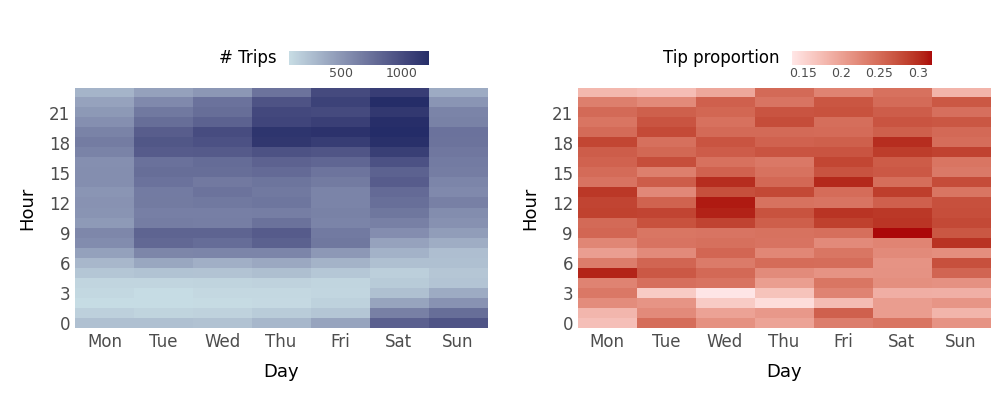

In [4]:
sampling = data.PlotSampler(EDA_SEED)
sample_n = min(SAMPLE_SIZE, len(trips))
days_sample = trips.iloc[sampling.indices(len(trips), sample_n)]
map_sample = trips.iloc[sampling.indices(len(trips), sample_n)]
publish("days", fig.time_heatmaps(days_sample))

## Where do trips begin and end?

The first map groups Chicago’s 77 community areas into ten regions. The pickup and drop-off maps then show where rides concentrate and how tipping varies across the city. [Community-area boundaries](https://data.cityofchicago.org/d/igwz-8jzy)

In each pair, marker size on the left reflects the number of rides around a reported centroid. The locations come from a second random sample of 100,000 trips. DBSCAN groups the centroids using a radius of 0.005 degrees and a minimum of five points. On the right, each area’s colour shows the share of **all complete rides** starting or ending there that had a recorded tip.

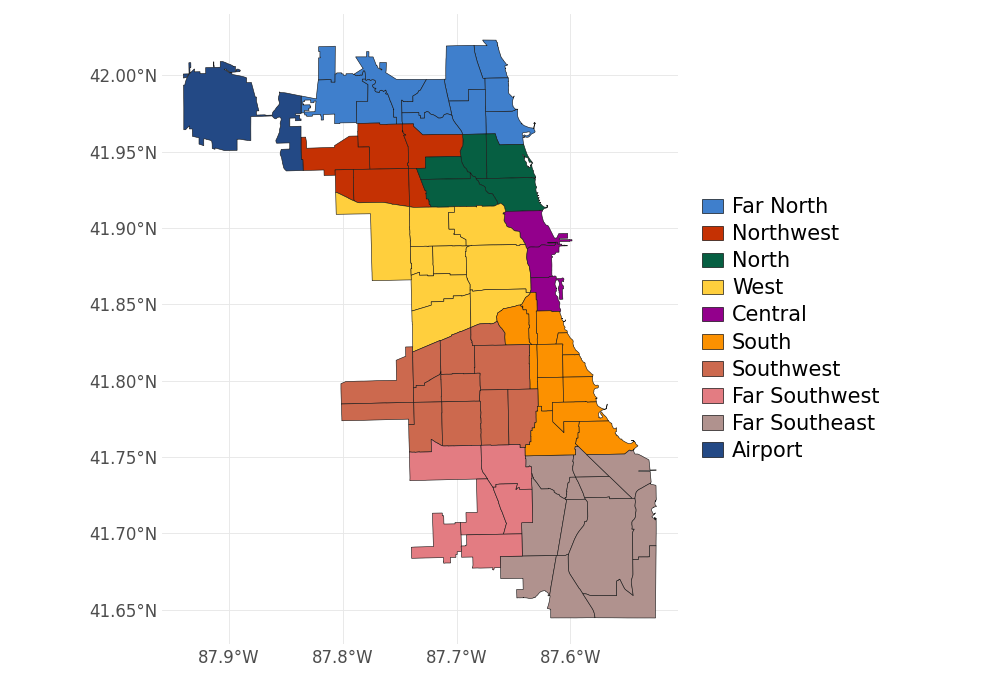

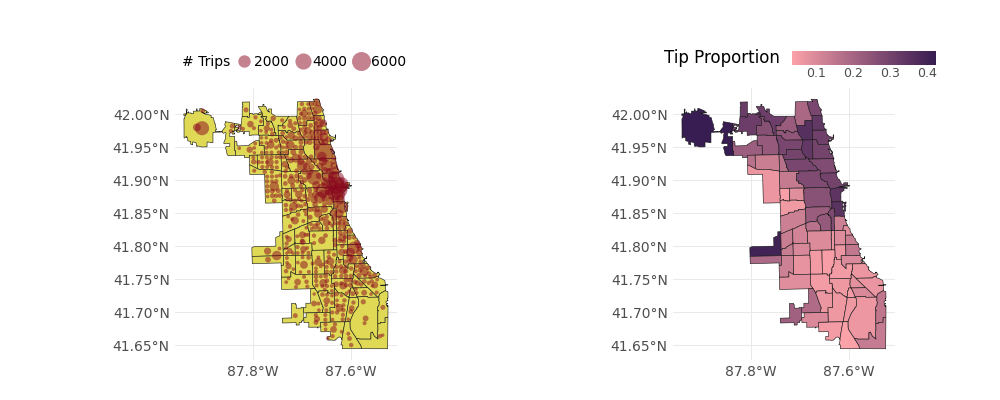

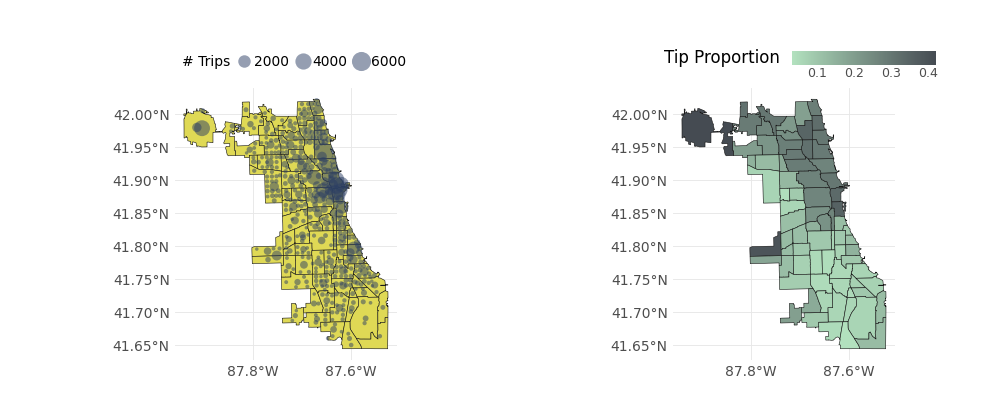

In [5]:
publish("map", fig.region_map(areas))
publish("pickup_map", fig.trip_maps(trips, map_sample, areas, "pickup"))
publish("dropoff_map", fig.trip_maps(trips, map_sample, areas, "dropoff"))

## Which routes have the highest tip rates?

Combining the ten map regions into five zones gives 15 possible routes. Each route counts both directions together. The Airport zone is the O’Hare community area.

The highest tip rate was **45.7%** across 251,955 rides between O’Hare and Central. At the other end of the chart, **7.3%** of 478,322 rides within the South zone had a recorded tip. The counts give each percentage its denominator.

,trips,tipped_trips,tip_rate
route,,,
Airport-Central,251955,115235,0.457363
Airport-Airport,12342,5259,0.426106
North-Airport,156329,63694,0.407436
West-Airport,77388,28039,0.362317
Central-Central,740600,249559,0.336969
South-Airport,18184,6114,0.336230
North-Central,689599,204061,0.295913
Central-West,881753,257758,0.292324
North-North,1017384,280256,0.275467


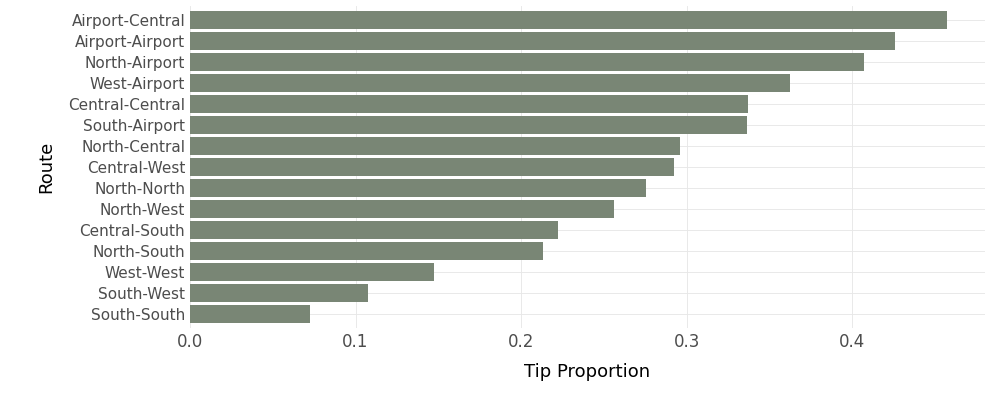

In [6]:
route_summary = (trips.groupby("route", observed=True).tip_given
                 .agg(trips="size", tipped_trips="sum", tip_rate="mean")
                 .sort_values("tip_rate", ascending=False))
table("routes", route_summary)
publish("routes", fig.routes_chart(trips))

## Fares, fees and pooled bookings

The correlation matrix and fare charts use the location sample. In that sample, **17.6%** of trips with fares up to USD 5 had a recorded tip, compared with **38.2%** for fares above USD 25. Both bar charts use the same cut points from eight fare quantile groups. Tied cut points merge, and the NA bar, when present, groups charges outside the sampled fare range.

The pooling chart uses all complete trips. A booking can cover several passengers. Here, one means the trip ran on its own and two means that two bookings shared the car. The recorded tip rate fell from **26.1%** for one booking to **7.7%** for two. The table links each observed booking count to the ordered index used in the models.

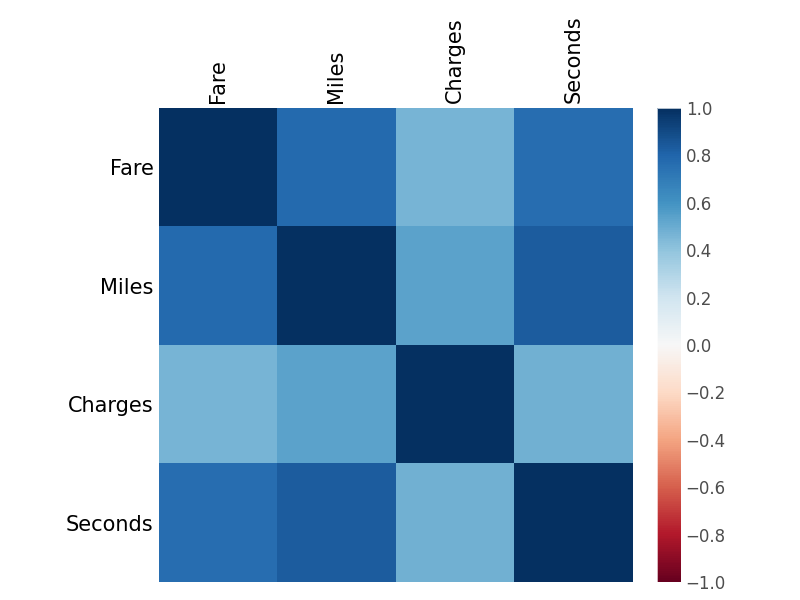

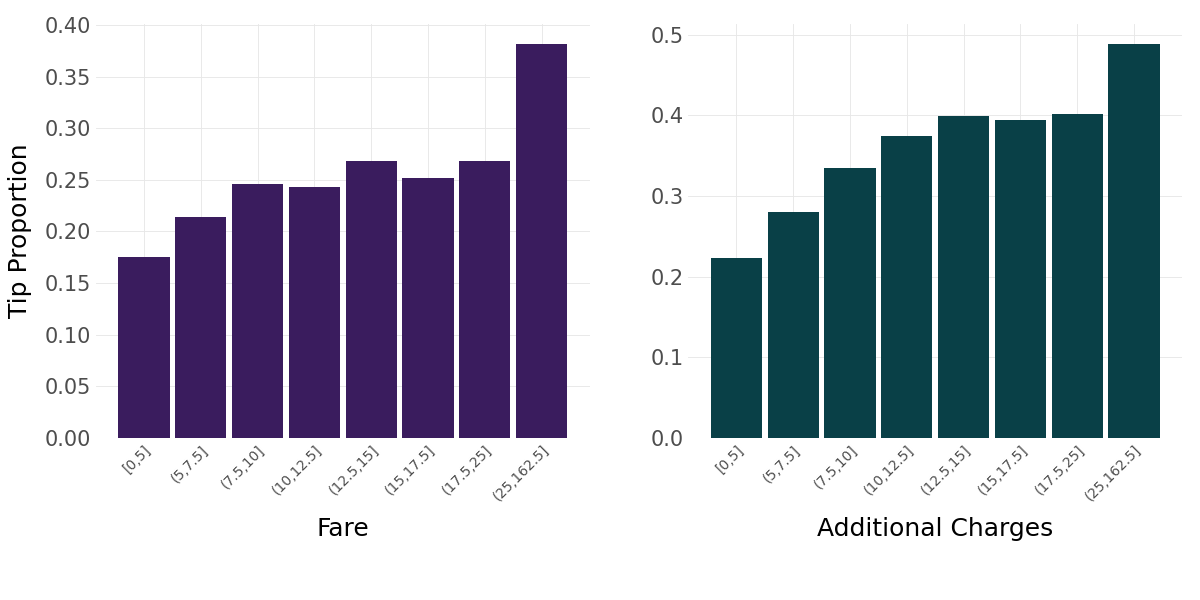

,,trips,tip_rate
pool_index,trips_pooled,,
1,1,6129721,0.260670
2,2,117457,0.077305
3,3,64018,0.070808
4,4,19194,0.058820
5,5,7783,0.038417
6,6,3980,0.024121
7,7,2167,0.010614
8,8,1483,0.007417
9,9,1059,0.002833


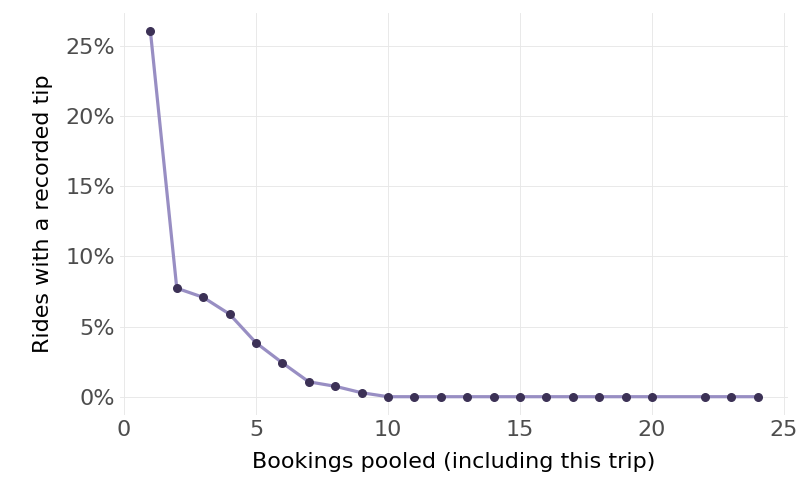

In [7]:
publish("correlation", fig.correlation_chart(map_sample))
publish("fare", fig.fare_chart(map_sample))
pool_summary = (trips.groupby(["pool_index", "trips_pooled"]).tip_given
                .agg(trips="size", tip_rate="mean"))
table("pool_levels", pool_summary)
publish("pooled", fig.pooling_chart(trips))

## Training and test design

Randomly sampling rides without a recorded tip to match the number with a tip produced a balanced cohort of 3,226,020 rides. A stratified 70/30 split assigned 2,258,214 rides to training and 967,806 to testing. Half the rides in each partition have a recorded tip.

Each route’s numeric predictor is its tip rate among **training rides only**. A route first encountered in the test set receives the overall training rate. Rides with identical predictors and outcomes are grouped for fitting and evaluation. Their trip counts supply the weights.

In [8]:
balanced, train_ids, test_ids = models.balance_and_split(trips, MODEL_SEED)
train, test, training_route_rates = models.encoded_pair(balanced.iloc[train_ids], balanced.iloc[test_ids])
x_train, x_test = models.design(train), models.design(test)
partitions = pd.DataFrame({
    "Rides": [len(trips), len(balanced), train.n, test.n],
    "Tip rate": [trips.tip_given.mean(), balanced.tip_given.mean(),
                 np.average(train.y, weights=train.w), np.average(test.y, weights=test.w)]
}, index=["Complete trips", "Balanced cohort", "Training", "Test"])
table("partitions", partitions)
table("training_route_encoding", training_route_rates.to_frame())

,Rides,Tip rate
Complete trips,6349902,0.254021
Balanced cohort,3226020,0.500000
Training,2258214,0.500000
Test,967806,0.500000


,Training tip rate
route,
North-North,0.527304
South-South,0.188953
Central-Central,0.598161
West-West,0.335591
Airport-Airport,0.684864
North-South,0.445060
North-Central,0.553613
Airport-Central,0.713384
North-West,0.503887


## Logistic regression

The model combines fare, additional charges, the pooling index, route tip rate, pickup period, weekend and a pickup-period × weekend interaction. The reference period is 07:00–15:00 on a weekday. Stepwise selection by Akaike information criterion (AIC) retained all terms.

Holding the other predictors fixed, a USD 10 higher fare corresponds to about **9% higher odds** of a recorded tip. Moving from one booking to two corresponds to about **46% lower odds**. Odds equal the probability of a recorded tip divided by the probability of a recorded zero.

In [9]:
with threadpool_limits(limits=1, user_api="blas"):
    glm = models.fit_glm(x_train, train.y, train.w)
    reduced, aic_steps, lr_test = models.stepwise_aic(x_train, train, glm)
coef = pd.DataFrame({"Coefficient": glm.params, "Std. error": glm.bse, "p-value": glm.pvalues})
table("logistic_coefficients", coef)
table("stepwise_aic", aic_steps)
table("aic_selected_coefficients", pd.DataFrame({"Coefficient": reduced.params,
                                                 "Std. error": reduced.bse, "p-value": reduced.pvalues}))
table("likelihood_ratio", lr_test.to_frame("Value"))
print(f"Full-model residual deviance: {glm.deviance:,.2f}")

Full-model residual deviance: 2,949,908.56


,Coefficient,Std. error,p-value
Intercept,-1.468741,0.010104,0.000000e+00
Fare,0.008218,0.000140,0.000000e+00
Additional.Charges,0.013872,0.000421,1.385992e-238
Trips.Pooled,-0.612681,0.006963,0.000000e+00
Part.of.Day2,0.027163,0.004213,1.136576e-10
Part.of.Day3,-0.214618,0.006302,3.414569e-254
Weekend1,0.026028,0.004693,2.918073e-08
Route.Mean,3.831715,0.012404,0.000000e+00
Part.of.Day2:Weekend1,-0.014146,0.006167,2.179484e-02
Part.of.Day3:Weekend1,-0.031901,0.008418,1.507695e-04


,Change,AIC
0,Full model,2.949929e+06


,Coefficient,Std. error,p-value
Intercept,-1.468741,0.010104,0.000000e+00
Fare,0.008218,0.000140,0.000000e+00
Additional.Charges,0.013872,0.000421,1.385992e-238
Trips.Pooled,-0.612681,0.006963,0.000000e+00
Part.of.Day2,0.027163,0.004213,1.136576e-10
Part.of.Day3,-0.214618,0.006302,3.414569e-254
Weekend1,0.026028,0.004693,2.918073e-08
Route.Mean,3.831715,0.012404,0.000000e+00
Part.of.Day2:Weekend1,-0.014146,0.006167,2.179484e-02
Part.of.Day3:Weekend1,-0.031901,0.008418,1.507695e-04


,Value
Reduced AIC,2.949929e+06
Full AIC,2.949929e+06
Likelihood-ratio statistic,0.000000e+00
df difference,0.000000e+00
p-value,NaN


Mean Pearson residual: -0.00164697


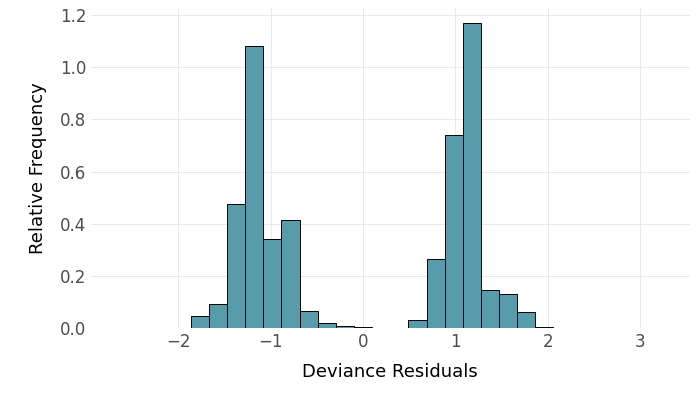

In [10]:
residuals, mean_pearson = models.diagnostics(train, glm.fittedvalues)
print(f"Mean Pearson residual: {mean_pearson:.8f}")
publish("deviance_residuals", fig.residual_hist(residuals, train.w))

## Lasso logistic regression

The Lasso penalises the absolute sizes of the logistic coefficients. Ten folds within the training set select the penalty with the lowest mean validation deviance. The solver standardises the predictors for fitting and returns coefficients in their original units. The weekend main effect and the overnight × weekend term both shrink to zero.

For the histogram below, let $q$ be the fitted probability assigned to the observed outcome. The plotted diagnostic has magnitude $\sqrt{2\log(1+1/q)}$ and the sign of the observed outcome minus the predicted tip probability. The preceding logistic histogram uses the usual binomial deviance residual, with magnitude $\sqrt{-2\log q}$. The two horizontal scales therefore differ.

Selected lambda: 0.0014874163
Mean Lasso Pearson residual: -0.00178680


,Coefficient
Intercept,-1.487614
Fare,0.007878
Additional.Charges,0.012835
Trips.Pooled,-0.554536
Part.of.Day2,0.011708
Part.of.Day3,-0.216877
Weekend1,0.000000
Route.Mean,3.797938
Part.of.Day2:Weekend1,0.002148
Part.of.Day3:Weekend1,0.000000


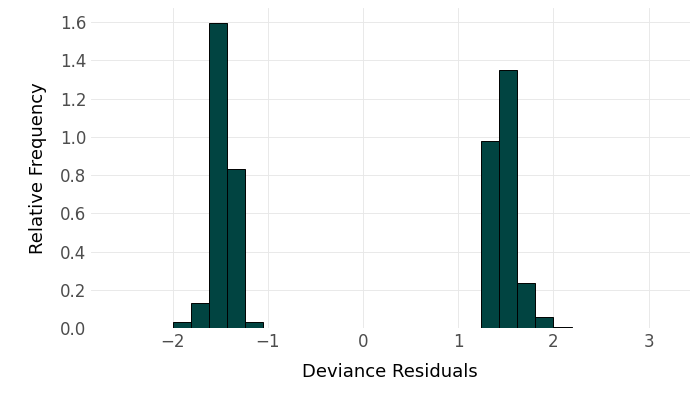

In [11]:
x_lasso = x_train.iloc[:, 1:].to_numpy()
with threadpool_limits(limits=1, user_api="blas"):
    lasso, lambda_cv = models.select_lasso(x_lasso, train, k=10, seed=MODEL_SEED)
print(f"Selected lambda: {lasso.penalty:.8g}")
lambda_cv.to_csv(TABLES_DIR / "lasso_cv_path.csv", index=False)
table("lasso_coefficients", pd.Series(np.r_[lasso.intercept, lasso.coefficient],
                                       index=x_train.columns, name="Coefficient").to_frame())
residuals_lasso, pearson_lasso = models.diagnostics(train, lasso.predict(x_lasso), lasso=True)
print(f"Mean Lasso Pearson residual: {pearson_lasso:.8f}")
publish("lasso_deviance_residuals", fig.residual_hist(residuals_lasso, train.w, lasso=True))

## Predicting a recorded tip

A logistic model predicts a tip when its fitted probability exceeds 0.5. The confusion matrices show the observed outcome in each row and the prediction in each column. On the balanced holdout, the full logistic model identified **75.8%** of tipped rides. Of the rides it flagged, **58.1%** had a recorded tip.

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.606187,0.581465,0.757920,0.658069
Lasso Regression,0.605666,0.580735,0.760061,0.658406


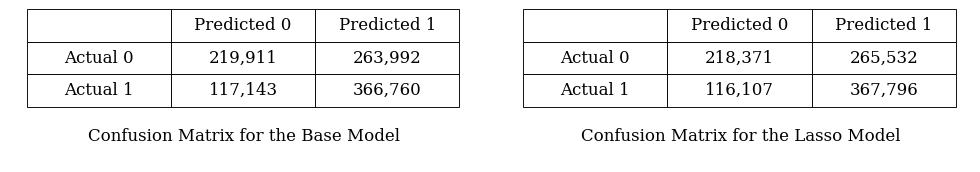

In [12]:
logistic_scores = {"Logistic Regression": glm.predict(x_test),
                   "Lasso Regression": lasso.predict(x_test.iloc[:, 1:].to_numpy())}
log_cm, log_metrics = models.classification_results(test, logistic_scores)
table("logistic_holdout_metrics", log_metrics)
publish("confusion_logistic", fig.confusion_tables({
    "Confusion Matrix for the Base Model": log_cm["Logistic Regression"],
    "Confusion Matrix for the Lasso Model": log_cm["Lasso Regression"]}))

### Five-fold ROC curves

Each ride in the balanced cohort is assigned to one of five folds. For each held-out fold, the route rates and both models are fitted on the other four. The Lasso reuses the penalty selected on the 70% training split. The table gives an AUC for each fold, and the curves pool the out-of-fold probability scores. The two models have nearly identical mean AUCs of about 0.651.

Model,Lasso Regression,Logistic Regression
Fold,,
1,0.650923,0.651138
2,0.651169,0.651355
3,0.651190,0.651418
4,0.651693,0.651884
5,0.651325,0.651439


,Mean fold AUC
Model,
Lasso Regression,0.651260
Logistic Regression,0.651447


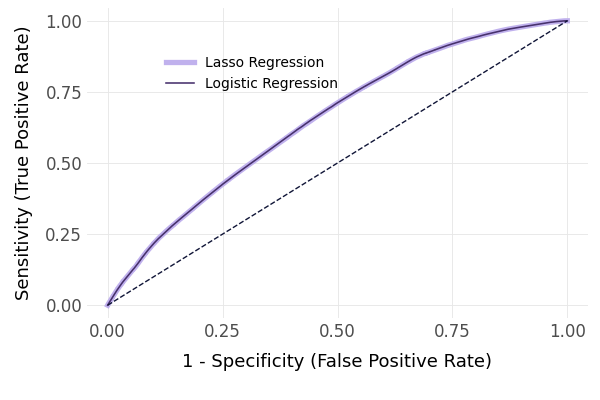

In [13]:
with threadpool_limits(limits=1, user_api="blas"):
    logistic_rocs, logistic_auc = models.cross_validated_rocs(balanced, lasso.penalty, seed=MODEL_SEED)
table("logistic_fold_auc", logistic_auc.pivot(index="Fold", columns="Model", values="AUC"))
display(logistic_auc.groupby("Model").AUC.mean().rename("Mean fold AUC").to_frame())
publish("roc_curve_logistic", fig.roc_chart(logistic_rocs))

## Classification tree and pruning

The classification tree splits on Gini impurity, with at least ten rides required to split a node and three per leaf. Pickup period and weekend enter as categorical predictors. The starting complexity parameter is 0.001. Each node shows its predicted class, the two class proportions and its share of training rides.

Ten-fold cross-validation on the training rides selected the starting complexity parameter, retaining all nine splits. The holdout predictions and variable importance use the fitted tree at 0.001. The route score accounts for **85.0%** of its total variable importance.

Selected CP: 0.001


,CP,splits,relative_error,xerror
0,0.187292,0,1.000000,1.001410
1,0.005006,1,0.812708,0.812708
2,0.003934,3,0.802695,0.802695
3,0.001100,5,0.794828,0.794828
4,0.001000,9,0.790430,0.792076


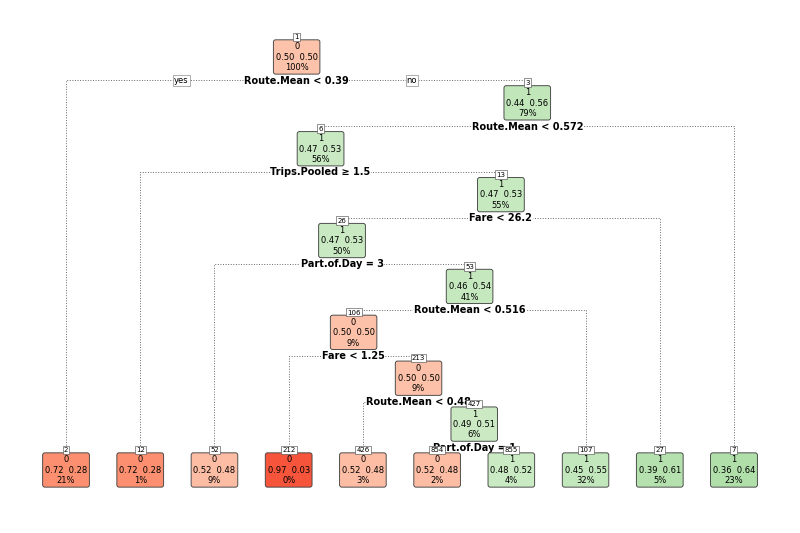

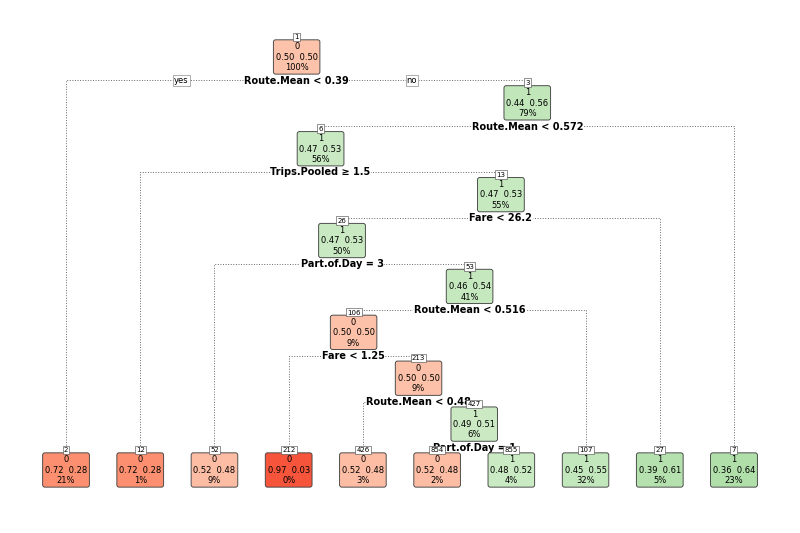

,Importance
Route.Mean,68425.109818
Fare,4691.505498
Trips.Pooled,3780.590761
Additional.Charges,2320.506182
Part.of.Day,1248.681847
Weekend,0.000000


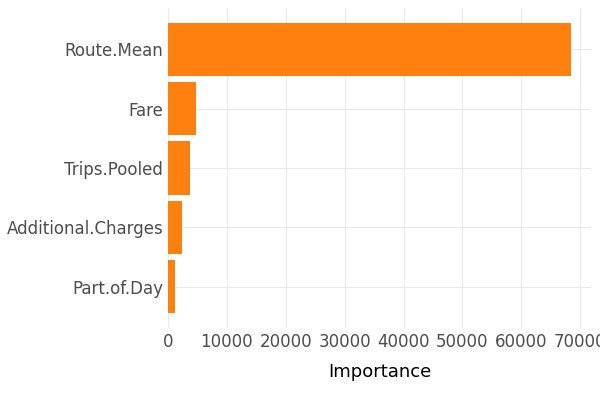

In [14]:
tree = trees.fit_tree(train, cp=.001)
pruned, cp_table = trees.select_pruning(train, tree, k=10, seed=MODEL_SEED)
table("pruning", cp_table)
print(f"Selected CP: {pruned.cp:.6g}")
publish("tree_plot", trees.tree_chart(tree))
publish("pruned_tree_plot", trees.tree_chart(pruned))
importance = trees.tree_importance(tree, train)
table("tree_importance", importance.to_frame())
publish("variable_importance_tree", fig.importance_chart(importance))

,Accuracy,Precision,Recall,F1
Model,,,,
Tree,0.605737,0.582854,0.743827,0.653575


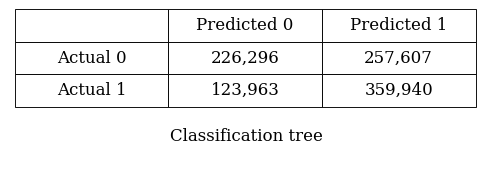

In [15]:
tree_cm, tree_metrics = models.classification_results(test, {"Tree": tree.classify(test.x)})
table("tree_holdout_metrics", tree_metrics)
publish("confusion_tree", fig.confusion_tables({"Classification tree": tree_cm["Tree"]}))

### Interpreting the tree ROC

For five-fold cross-validation, the tree is fitted with a complexity parameter of 0.005 and assigns each ride a binary class. Those two possible scores produce just one interior point on its ROC curve. The logistic curves use fitted probabilities across many thresholds. This difference in scoring matters when interpreting the mean AUCs.

Mean fold AUC: 0.5989


,AUC
Fold,
1,0.598644
2,0.599334
3,0.599037
4,0.598666
5,0.598659


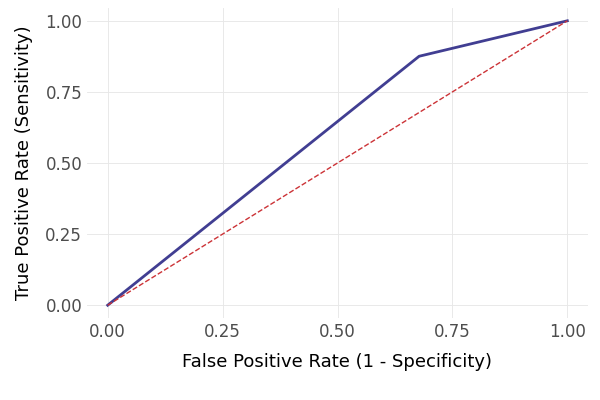

In [16]:
tree_rocs, tree_auc = models.cross_validated_rocs(balanced, k=5, seed=MODEL_SEED, tree=True)
table("tree_fold_auc", tree_auc.set_index("Fold")[["AUC"]])
print(f"Mean fold AUC: {tree_auc.AUC.mean():.4f}")
publish("roc_curve_tree", fig.roc_chart(tree_rocs, tree=True))

## Model comparison

Accuracy, precision, recall and F1 below describe the same 967,806 balanced test rides. The final column averages AUC across the five folds of the balanced cohort. All three models correctly classify about 61 rides per 100 on the holdout, where always predicting one class would classify 50 correctly.

[Exported figures](report/plots/) · [Numerical tables](report/tables/)

In [17]:
all_auc = pd.concat([logistic_auc, tree_auc], ignore_index=True).groupby("Model").AUC.mean()
summary = pd.concat([log_metrics, tree_metrics]).join(all_auc.rename("Mean fold AUC"))
table("model_summary", summary)
expected = {"days", "map", "pickup_map", "dropoff_map", "routes", "correlation", "fare", "pooled",
            "deviance_residuals", "lasso_deviance_residuals", "confusion_logistic", "roc_curve_logistic",
            "tree_plot", "pruned_tree_plot", "variable_importance_tree", "confusion_tree", "roc_curve_tree"}
assert set(published) == expected, f"Missing analyses: {expected - set(published)}"
for paths in published.values():
    assert all(path.is_file() and path.stat().st_size > 0 for path in paths)
print(f"{len(published)} figures × {len(FORMATS)} formats saved in {PLOTS_DIR.relative_to(ROOT)}/")
print(f"Numerical tables saved in {TABLES_DIR.relative_to(ROOT)}/")

17 figures × 2 formats saved in report/plots/
Numerical tables saved in report/tables/


,Accuracy,Precision,Recall,F1,Mean fold AUC
Model,,,,,
Logistic Regression,0.606187,0.581465,0.757920,0.658069,0.651447
Lasso Regression,0.605666,0.580735,0.760061,0.658406,0.651260
Tree,0.605737,0.582854,0.743827,0.653575,0.598868


## What should the app test?

Even on O’Hare–Central, the route with the highest tip rate, **54.3% of rides had no recorded tip**. The records cover one city and one month. They omit rider tipping history, trip ratings and the prompt the app displayed. Testing the model on a later month with the usual share of tipped rides would show how well its predictions transfer.

The presentation proposes a randomised experiment. Within each predicted class, assign riders equally to the standard suggestion or a tailored one. The tailored version would suggest a higher amount to riders predicted to tip and a lower amount to the other group. Compare **mean in-app tip dollars per ride** between the two arms, including zero-tip rides in both. That difference would measure whether the new prompt increases driver tip income.